In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeRegressor, plot_tree

I want to try and understand the code, what its doing and what's going on, whilst also understanding the ML technique we are applying

So what we are doing;

- Reading a small database of measured neutron capture cross section and summarizing it
- Training a decision tree on every isotope __except__ gold-197
- Then ask the tree for its prediction for gold-197 based on the training data, plot it against the EXFOR measurement + the ENDF evaluation
- Inspect what the tree is asking
- Ask how honest this test is, what question does it answer?
- Give the tree more features to see how it changes
- Then tune the tree, compare it with XGBoost and a random forest

In [2]:
### Loading in the data

filepath = Path("../data/teaching")

db = pd.read_csv(filepath / "capture_cleaned.csv")   ### Cleaned neutron cross section data
ev = pd.read_csv(filepath / "endf_Au197_capture.csv") ## Evaluated curve of gold

db.head()


,entry,Z,A,energy_eV,sigma_b
0,11235005,5,11,139000.0,0.000008
1,11235005,5,11,198000.0,0.000013
2,11235005,5,11,238000.0,0.000010
3,11235005,5,11,287000.0,0.000010
4,11235005,5,11,336000.0,0.000016


We see that for the cleaned database, the structure is the entry (the EXFOR entry it comes from), 
- Z = proton number
- A = nucleon number
- energy_eV = Neutron energy in electron volts
- sigma_b = Cross section, in barns 

We want to summarise this data..

In [3]:
num_entries = len(db)
isotopes = db.groupby(["Z", "A"]).ngroups

print(f"There are a total of {num_entries} EXFOR entries, with {isotopes} different isotopes")

points_per_isotope = db.groupby(["Z", "A"]).size().describe().round(0).to_string()

print("A summary of how much data (rows) there is per isotope:")
print(points_per_isotope)

There are a total of 7624 EXFOR entries, with 83 different isotopes
A summary of how much data (rows) there is per isotope:
count     83.0
mean      92.0
std       72.0
min       31.0
25%       45.0
50%       69.0
75%       98.0
max      300.0


Now we want to visualize this data, we will plot all these cross sections, including gold

This will be logarithmic as to not skew the plot heavily

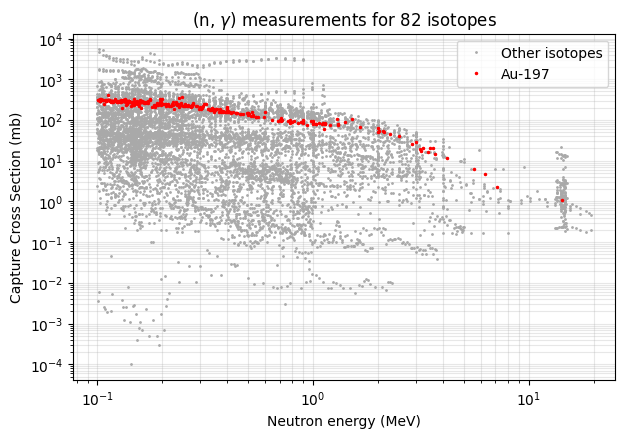

In [4]:
## Create figure + axes
fig, ax = plt.subplots(figsize=(7,4.5))

## Plotting the isotopes

ax.plot(db.energy_eV / 1e6, db.sigma_b * 1000, ".", color="darkgray", ms=2, label="Other isotopes")

## Getting the gold measurements;
gold = db[(db.Z == 79) & (db.A == 197)]

ax.plot(gold.energy_eV / 1e6, gold.sigma_b * 1000, ".", ms=3, color='red', label="Au-197")
ax.set(xscale = "log", yscale= "log", xlabel="Neutron energy (MeV)", ylabel="Capture Cross Section (mb)", title=r"(n, $\gamma$) measurements for 82 isotopes")
ax.grid(which="both", alpha=0.3); ax.legend()

plt.show()

Now we want to prepare the data for machine learning, first by preparing features...

__features__: Z, A and neutron energy
__target__: Cross section

I.e we are using Z,A and neutron energy to predict a value for cross section

We are working in log base 10 so that the very large cross sections do not dominate what the model learns

In [5]:
### Defining our model features

db["logE"] = np.log10(db.energy_eV)   ## log10 of the energy in eV
db["logS"] = np.log10(db.sigma_b *1000)  ## log10 of cross section in mb

features = ["Z", "A", "logE"]         ## Defining an object (list) that contains all our features we want

We also will want to remove gold from our training set if it is the benchmark we are using to test the model on an isotope that it has never seen

In [6]:
test_set = db[(db.Z == 79) & (db.A == 197)]
training_set = db.drop(test_set.index) 

training_set.logS

0      -2.091515
1      -1.896196
2      -1.978811
3      -1.987163
4      -1.801343
          ...   
7619    1.724276
7620    1.716003
7621    1.623249
7622    1.462398
7623    1.447158
Name: logS, Length: 7324, dtype: float64

Now we want to train a decision tree...

The tree learns a list of yes/no questions about given features (e.g. is Z above 28? is energy above 1MeV?) where each question splits the training points into two groups. At the end of a branch (called a leaf) the tree predicts the average of the training points that landed there.

__Loss Function__: The algorithm needs to decide _which_ question to ask. It will try many candidates and keeps the one that makes predictions the best, which is quantified by the loss function. Here we use a squared error on the log10 cross section as our loss function; the sum of (prediction - measured value)$^2$ over all training points


We also control two hyperparemeters:
- max_depth; longest chain of questions
- min_samples_leaf; the smallest group allowed at a leaf

In [7]:
### Training the model;

tree = DecisionTreeRegressor(criterion="squared_error", max_depth=8, min_samples_leaf=5, random_state=0)

tree.fit(training_set[features], training_set.logS)        ## Trains on our features and target values logS



,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

Using our fitted tree model...

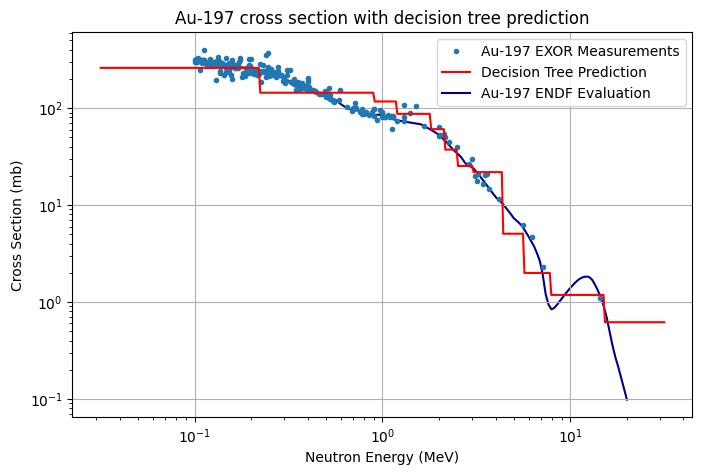

In [8]:
## Define a dataset with Z= 79 and A = 197 on every row and range of energies

E = np.logspace(4.5, 7.5, 400)
grid = pd.DataFrame({"Z": 79, "A" : 197, "logE" : np.log10(E)})

prediction = 10 ** tree.predict(grid)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(test_set.energy_eV / 1e6, test_set.sigma_b * 1000, '.', label='Au-197 EXOR Measurements')
ax.plot(E / 1e6 , prediction, color='red', label='Decision Tree Prediction')
ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, '-',color='darkblue', zorder=1, label='Au-197 ENDF Evaluation')
ax.set(xscale='log', yscale='log', xlabel='Neutron Energy (MeV)', ylabel='Cross Section (mb)', title='Au-197 cross section with decision tree prediction')
ax.grid() ; ax.legend()

plt.show()

How do we quantify how good this fit is?

Training minimises the mean squared error (MSE) of the log10 cross sections, so we want to look at the root mean square error converted back from log10

- RMS Factor = 10 $^{\text{RMSE}}$

Result of 1.0 would be perfect (i.e RMSE = 0)

Squaring punishes large errors, so a few wild points can dominate the RMS factor, so we can also print the median factor (median of absolute log10 differences, converted back) which will ignroe wild points and shows what a typical point looks like.

When these two quantities are close, it means that the errors are evenly spread. When RMS factor >> median factor, a few points are very wrong 

In [9]:
def errors(model, df, feats=features):
    ## Returns (RMS factor, Median Factor) of the model on df
    r = model.predict(df[feats]) - df.logS

    return 10** np.sqrt(np.mean(r ** 2)), 10 ** np.median(np.abs(r))

rms_original, med_original = errors(tree, test_set)

print(f'Against EXFOR points of Au-197: RMS factor = {rms_original:.2f} (around {100* (rms-1):.2f}%) | median factor = {med_original:.2f} | Relative difference = {np.abs(rms_original - med_original):.3f}')


NameError: name 'rms' is not defined

Now we want to look inside the tree..

We set max_depth = 8 so we expect the tree to be 8 questions in a row

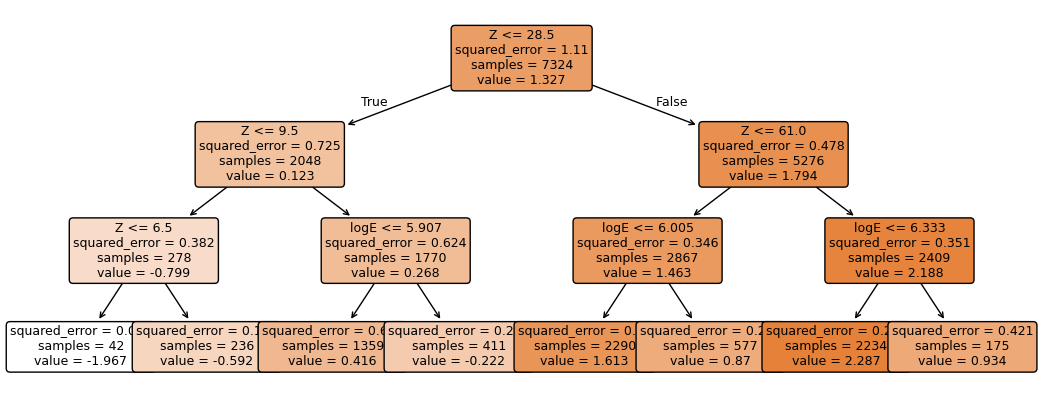

In [ ]:
small_tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(training_set[features], training_set.logS)
fig, ax = plt.subplots(figsize=(13,5))
plot_tree(small_tree, feature_names = features, filled=True, rounded=True, impurity=True, fontsize=9, ax=ax)
plt.show()

How honest is this test?

If we included some gold data points in the test set, then we are asking a different question: "How well can the model fill the gaps of an isotope that has been measured?" Slightly easier than the former case.

Another thing to consider is that there are many isotopes that look very similar to gold, so the algorithm just has to find data points that are very similar to gold and copy them. Then, the model only tells us that gold has neighbours that are almost copies of it. A harder and more honest test would be to pick a target with few look-alikes, or even removing whole regions of nuclides from training (e.g every isotope with Z > 60)

#### Does the tree do better with more feautures?

We only trained the tree on Z, A and neutron energy

We know a lot more about the nucleas, we can see in isotope_features.csv ---> We have a total of 10 features.
What if we repeat, this time training on 10 features?

In [ ]:
### Investigating the look-alikes
def held_out_factor(train_df, test_df, **settings):
    m = DecisionTreeRegressor(random_state=0, **settings).fit(train_df[features], train_df.logS)
    return errors(m, test_df)[0]


bins = np.floor(db.logE * 8)            ## group into energy intervals
curve = db.groupby([db.Z, db.A, bins]).logS.median().unstack([0,1])
shared = curve.notna().mul(curve[(79,197)].notna(), axis=0).sum()

distance = curve.sub(curve[(79,197)], axis=0).abs().median()[shared >= 4].drop((79, 197))
look_alikes = distance[distance < 0.3].index

print(f'There are {len(look_alikes)} out of {len(distance)} comparable isotopes that lie within a factor of 2 gold; the median isotope is off by a factor of {10 ** distance.median():.1f} ')

train_hard = training_set[~training_set.set_index(["Z", "A"]).index.isin(look_alikes)]

print(f'Tree from before, trained without the look-alikes: RMS factor = {held_out_factor(train_hard, test_set, max_depth=8, min_samples_leaf=5):.2f}')

There are 24 out of 76 comparable isotopes that lie within a factor of 2 gold; the median isotope is off by a factor of 3.6 
Tree from before, trained without the look-alikes: RMS factor = 4.04


In [ ]:
db10 = db.merge(pd.read_csv(filepath / "isotope_features.csv"), on=["Z", "A"])

features10 = features + ["N", "Q_capture", "S_n", "B_per_A", "Z_odd", "N_odd", "N_magic_dist"]
## Test set again
test10 = db10[(db10.Z == 79) & (db10.A == 197)]
## Training set again
train10 = db10.drop(test10.index)

### Dropping the look alikes now:
hard10 = train10[~train10.set_index(["Z", "A"]).index.isin(look_alikes)]

def fit_and_score(feats):
    fit = lambda df: DecisionTreeRegressor(criterion="squared_error", max_depth=8, min_samples_leaf=5, random_state=0).fit(df[feats], df.logS)
    model= fit(train10)
    return model, errors(model, test10, feats), errors(fit(hard10), test10, feats)[0]

model3, (rms3, med3), hard3 = fit_and_score(features)

model10, (rms10, med10), hard10_rms = fit_and_score(features10)


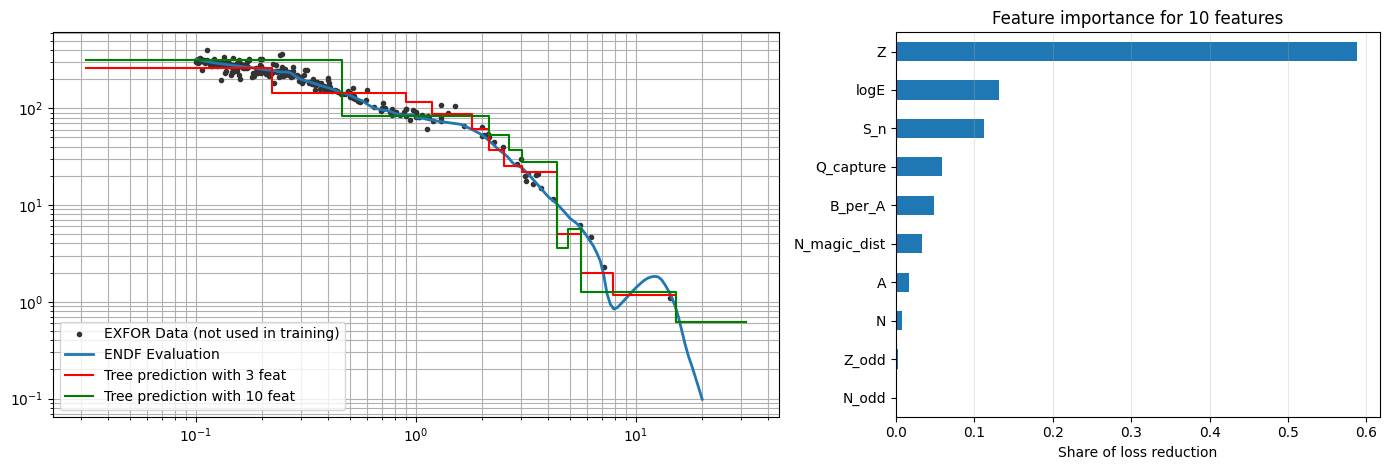

In [ ]:
grid10 = test10[features10].iloc[[0] * len(E)].reset_index(drop=True)
grid10["logE"] = np.log10(E)

fig, ax = plt.subplots(1, 2, figsize=(14,4.8), gridspec_kw={"width_ratios": [3,2]})

ax[0].plot(test_set.energy_eV / 1e6, test_set.sigma_b * 1000, ".", color='0.2', label='EXFOR Data (not used in training)')
ax[0].plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "-", lw=2, label="ENDF Evaluation")
ax[0].plot(E / 1e6, prediction, "-r", drawstyle="steps-mid", label="Tree prediction with 3 feat")
ax[0].plot(E / 1e6, 10 ** model10.predict(grid10[features10]), "-", color='green', drawstyle="steps-mid", label="Tree prediction with 10 feat")

ax[0].set(xscale="log", yscale="log") ; ax[0].grid(which='both') ; ax[0].legend()

pd.Series(model10.feature_importances_, index=features10).sort_values().plot.barh(ax=ax[1], color="tab:blue")
ax[1].set(xlabel="Share of loss reduction", title= "Feature importance for 10 features") ; ax[1].grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.show()

What do we see from this?

More features doesn't necessarily mean better results, and for this case, all the new properties are properties of the isotope themselves, thus don't change with e.g. neutron energy. There are 82 isotope examples, so it is just memorising what isotopes are what, and thus struggles with an unseen isotope like here.

Good features for training are one that matter in physics, for example energy released by capture. A decision tree that finds this out from 82 isotopes may not see this as an important feature, and we see that Z is by far the most important feature in the training set. 

#### Now we want to change some things...

#### Hyperparemeters?

Our hyperparameters were max_depth and min_samples_leaf, so we should try and tweak these...

We will want to plot RMS factor and median factor against tree depth to see if there is an improvement

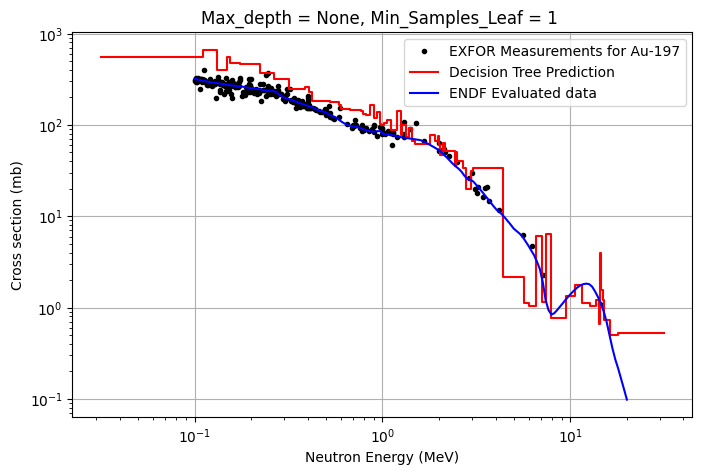

In [ ]:
## Hyperparameters;

depth = None
msl = 1

tree_tweaked = DecisionTreeRegressor(criterion="squared_error", max_depth= depth, min_samples_leaf= msl, random_state=0)
tree_tweaked.fit(training_set[features], training_set.logS)

## Prediction

tweaked_prediction = 10 ** tree_tweaked.predict(grid)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(test_set.energy_eV / 1e6, test_set.sigma_b * 1000, ".", color='black', label="EXFOR Measurements for Au-197")
ax.plot(E / 1e6, tweaked_prediction, "r-", drawstyle="steps-mid", label="Decision Tree Prediction")
ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, color='blue', label='ENDF Evaluated data')
ax.set(xscale='log', yscale='log', xlabel="Neutron Energy (MeV)", ylabel = "Cross section (mb)", title=f"Max_depth = {depth}, Min_Samples_Leaf = {msl} ")
ax.grid() ; ax.legend()
plt.show()

For an unlimited max depth and the lowest minimum leaf sample requirement, we see very obvious overfitting. This is most likely due to the discrete nature of the decision tree - it only sorts into 'bins' (leafs). 

## Tweaking depth + msl

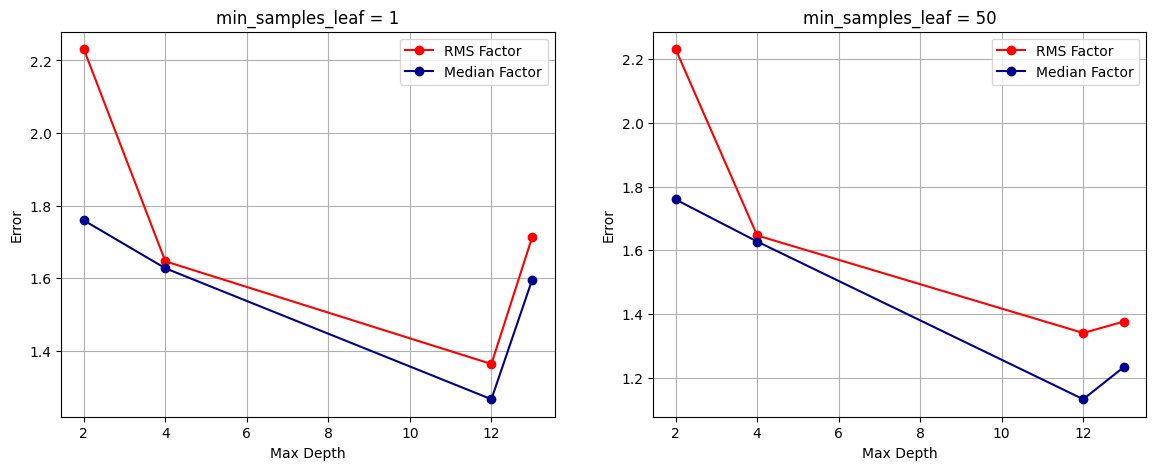

In [ ]:
### Want to try and be concise with this

depths = [2, 4, 12, None]

results_1 = []

## Cycling through different depth sizes:

for i in depths:
    tree_tweaked = DecisionTreeRegressor(
        criterion = "squared_error",
        max_depth = i,
        min_samples_leaf = 1,
        random_state= 0
    )
    tree_tweaked.fit(training_set[features], training_set.logS)

    ## Prediction
    tweaked_prediction = 10 ** tree_tweaked.predict(grid)

    ## Actual values
    actual = test_set.sigma_b

    rms, med = errors(tree_tweaked, test_set)        

    results_1.append({
        "max_depth" : i,
        "min_samples_leadf" : 1,
        "RMS_factor" : rms,
        "Median_factor" : med,
    })


##### Second loop with msl = 50

results_50 = []

for i in depths:
    tree_tweaked = DecisionTreeRegressor(
        criterion = "squared_error",
        max_depth = i,
        min_samples_leaf = 50,
        random_state= 0
    )
    tree_tweaked.fit(training_set[features], training_set.logS)

    ## Prediction
    tweaked_prediction = 10 ** tree_tweaked.predict(grid)

    ## Actual values
    actual = test_set.sigma_b

    rms, med = errors(tree_tweaked, test_set)        

    results_50.append({
        "max_depth" : i,
        "min_samples_leadf" : 1,
        "RMS_factor" : rms,
        "Median_factor" : med,
    })



results1_df = pd.DataFrame(results_1)
x1 = results1_df["max_depth"].fillna(13)

results50_df = pd.DataFrame(results_50)
x2 = results50_df["max_depth"].fillna(13)


figs, ax = plt.subplots(1,2, figsize=(14,5))

ax[0].plot(
    x1, 
    results1_df['RMS_factor'], "o-", color = "red",
    label="RMS Factor")
ax[0].plot(
    x1, 
    results1_df["Median_factor"], "o-", color="darkblue",
    label = "Median Factor")

ax[1].plot(
    x2,
    results50_df["RMS_factor"], "o-",color='red',
    label= "RMS Factor")

ax[1].plot(
    x2,
    results50_df["Median_factor"], "o-",color="darkblue",
    label= "Median Factor"
)

ax[0].set(
    xlabel = "Max Depth",
    ylabel = "Error",
    title = "min_samples_leaf = 1"
)

ax[1].set(
    xlabel= "Max Depth",
    ylabel = "Error",
    title = "min_samples_leaf = 50"

)

ax[0].legend() ; ax[0].grid()
ax[1].legend() ; ax[1].grid()

plt.show()


## Changing the loss function

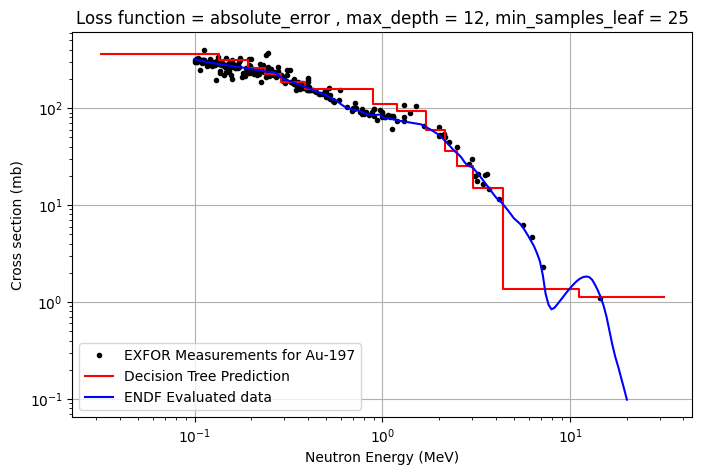

RMS Factor Error = 1.27, Median Factor = 1.17


In [ ]:
msl = 25

tree_abs = DecisionTreeRegressor(criterion="absolute_error", max_depth= 12, min_samples_leaf= msl, random_state=0)
tree_abs.fit(training_set[features], training_set.logS)

## Prediction


tree_abs_prediction = 10 ** tree_abs.predict(grid)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot(test_set.energy_eV / 1e6, test_set.sigma_b * 1000, ".", color='black', label="EXFOR Measurements for Au-197")
ax.plot(E / 1e6, tree_abs_prediction, "r-", drawstyle="steps-mid", label="Decision Tree Prediction")
ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, color='blue', label='ENDF Evaluated data')
ax.set(xscale='log', yscale='log', xlabel="Neutron Energy (MeV)", ylabel = "Cross section (mb)", 
       title=f"Loss function = absolute_error , max_depth = 12, min_samples_leaf = {msl}")
ax.grid() ; ax.legend()
plt.show()

abs_rms, abs_med = errors(tree_abs, test_set)   

print(f'RMS Factor Error = {abs_rms:.2f}, Median Factor = {abs_med:.2f}')

## Holdout on other isotopes

Specifically (92, 238) for Uranium-238 and (73, 181) for Tantalum-181

In [ ]:
## First, uranium

ev_u = pd.read_csv(filepath / "endf_U238_capture.csv")

test_u = db[(db.Z == 92) & (db.A == 238)]
train_u = db.drop(test_u.index)

## Hyperparameters:

depth = 8
msl = 1

tree_u = DecisionTreeRegressor(criterion="squared_error", max_depth = depth, min_samples_leaf= msl, random_state=0)
tree_u.fit(train_u[features], train_u.logS)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

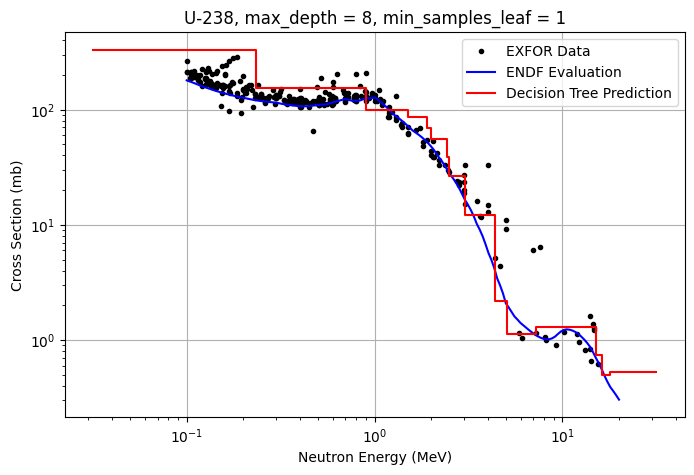

The RMS factor error = 1.62, the median factor = 1.33


In [ ]:
## Prediction..

E = np.logspace(4.5, 7.5, 400)  ## Energy space as before
grid = pd.DataFrame({"Z": 92, "A":238, "logE": np.log10(E)})
u_prediction = 10 ** tree_u.predict(grid)

u_rms, u_med = errors(tree_u, test_u)

## Plotting this...

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(test_u.energy_eV / 1e6, test_u.sigma_b * 1000, ".", color='0', label= "EXFOR Data")
ax.plot(ev_u.energy_eV / 1e6, ev_u.sigma_b * 1000, color='blue', label= 'ENDF Evaluation')
ax.plot(E / 1e6, u_prediction, "-r", drawstyle='steps-mid', label='Decision Tree Prediction')

ax.set(
    xscale = "log",
    yscale = "log",
    xlabel= "Neutron Energy (MeV)",
    ylabel = "Cross Section (mb)",
    title = f"U-238, max_depth = {depth}, min_samples_leaf = {msl}"
)

ax.grid() ; ax.legend()

plt.show()

print(f'The RMS factor error = {u_rms:.2f}, the median factor = {u_med:.2f}')

In [ ]:
## Now we hold out tantalum...

ev_t = pd.read_csv(filepath / "endf_Ti47_np.csv")

test_t = db[(db.Z == 73) & (db.A == 181)]
train_t = db.drop(test_t.index)

## Hyperparameters:

depth = 8
msl = 1

tree_t = DecisionTreeRegressor(criterion="squared_error", max_depth = depth, min_samples_leaf= msl, random_state=0)
tree_t.fit(train_t[features], train_t.logS)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``m

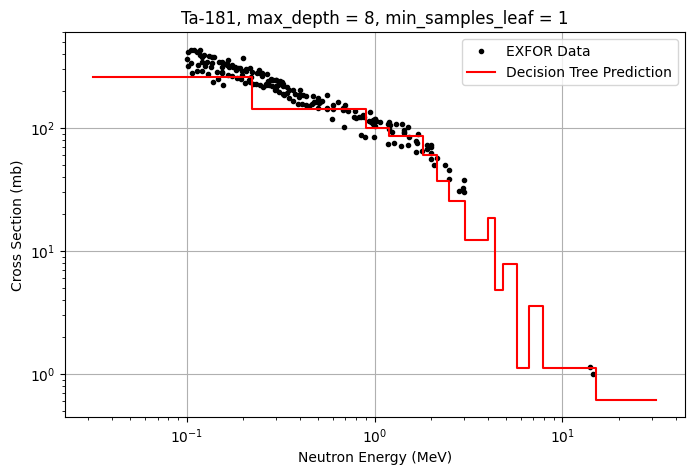

The RMS factor error = 1.67, the median factor = 1.30


In [ ]:
## Prediction..

grid = pd.DataFrame({"Z": 92, "A":238, "logE": np.log10(E)})
t_prediction = 10 ** tree_t.predict(grid)

t_rms, t_med = errors(tree_t, test_t)

## Plotting this...

fig, ax = plt.subplots(figsize=(8,5))

ax.plot(test_t.energy_eV / 1e6, test_t.sigma_b * 1000, ".", color='0', label= "EXFOR Data")
#ax.plot(ev_t.energy_eV / 1e6, ev_t.sigma_b * 1000, color='blue', label= 'ENDF Evaluation')
ax.plot(E / 1e6, t_prediction, "-r", drawstyle='steps-mid', label='Decision Tree Prediction')

ax.set(
    xscale = "log",
    yscale = "log",
    xlabel= "Neutron Energy (MeV)",
    ylabel = "Cross Section (mb)",
    title = f"Ta-181, max_depth = {depth}, min_samples_leaf = {msl}"
)

ax.grid() ; ax.legend()

plt.show()

print(f'The RMS factor error = {t_rms:.2f}, the median factor = {t_med:.2f}')

Note that the reaction for ENDF is np, not capture, thus the evaluated spectrum is different (I have excluded it)

## Hyperparameters via optimisation

We want to implement a hyperparameter optimisation that picks the best parameters for us

Could use grid search, random search or optuna...

How do we score each trial? 

In [ ]:
## Try GridSearchCV

from sklearn.model_selection import GridSearchCV, GroupKFold

## Which isotope does each measurement belong to?

groups = db['Z'].astype(str) + "_" + db["A"].astype(str)

## Defining hyperparams;

param_grid = {
    "max_depth" : [2,4,8,12,None],
    "min_samples_leaf" : [1,5,20,50]
}

## Split by isotope, not individual measurements

cv = GroupKFold(n_splits=5)

## Search

search = GridSearchCV(
    estimator = DecisionTreeRegressor(random_state=0),
    param_grid = param_grid,
    scoring = "neg_mean_squared_error",
    cv =cv,
    n_jobs = -1
)

## Train and compare params:

search.fit(db[features], db["logS"], groups=groups)

print(f"Best parameters: {search.best_params_}")
print(f"Best cross-validation RMSE: {np.sqrt(-search.best_score_):.2f}, or as a factor: {10 ** np.sqrt(-search.best_score_):.2f}")

best_tree = search.best_estimator_

Best parameters: {'max_depth': 8, 'min_samples_leaf': 20}
Best cross-validation RMSE: 0.62, or as a factor: 4.16


What have we done here?

- param_grid tests 5x4 = 20 combinations of tree depth and min leaf size 
- GroupKFold has split the isotopes into five groups of folds --> each round trains roughly on 4/5 of the isotope groups, and validates on the remaining groups.

- neg_mean_squared_error scores the squared difference between predicted and actual logS values. Scikit-Learn convention is that higher scores are better, we negate before taking square root to get RMSE

- best_estimator gives decision tree with the best average cross-validation score. We can then evaluate it on the held-out gold data

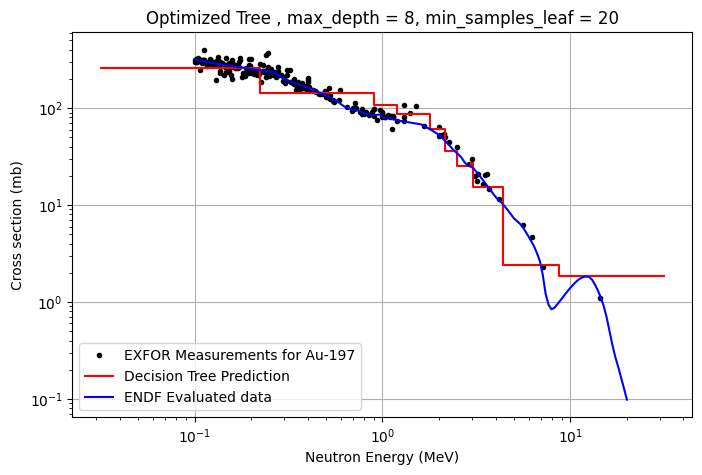

For the tuned decision tree: RMS Error = 1.28, Median = 1.15
And our original tree: RMS Error = 1.29, Median = 1.15


In [ ]:
## Lets evaluate gold with this optimized tree:

best_tree.fit(training_set[features], training_set.logS)

g_prediction = 10 ** best_tree.predict(grid)


fig, ax = plt.subplots(figsize=(8,5))
ax.plot(test_set.energy_eV / 1e6, test_set.sigma_b * 1000, ".", color='black', label="EXFOR Measurements for Au-197")
ax.plot(E / 1e6, g_prediction, "r-", drawstyle="steps-mid", label="Decision Tree Prediction")
ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, color='blue', label='ENDF Evaluated data')
ax.set(xscale='log', yscale='log', xlabel="Neutron Energy (MeV)", ylabel = "Cross section (mb)", 
       title=f"Optimized Tree , max_depth = 8, min_samples_leaf = 20")
ax.grid() ; ax.legend()
plt.show()

rms, med = errors(best_tree, test_set)

print(f'For the tuned decision tree: RMS Error = {rms:.2f}, Median = {med:.2f}')
print(f'And our original tree: RMS Error = {rms_original:.2f}, Median = {med_original:.2f}')

We see that hyperparameter tuning hasn't really made that much of a difference to our result, with only a 0.01 change in the RMSE and median exactly the same. 

This tells us that for gold in particular, the tuning didn't help

Need to work on this more...

## Comparing with XGBoost and Random Forest

- Random Forest = Combines lots of decision trees
- XGBoost = Builds trees sequentially, each tree tries to correct the previous one's errors

We want to test them fairly, therefore we hold out entire isotopes, train on the others, then evaluate against the held out isotopes.

In [34]:
import time

from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

## Hold out on Gold measurements
test_mask = (db.Z == 79) & (db.A == 197)
train = db.loc[~test_mask].copy()
test = db.loc[test_mask].copy() 

X_train = train[features]
y_train = train["logS"]

X_test = test[features]
y_test = test["logS"]

## Each isotope = one group for cross-validation

groups = train["Z"].astype(str) + "_" + train["A"].astype(str)
cv = GroupKFold(n_splits = 5)

In [42]:
## Training

models = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=0),
        {
            "max_depth" : [2,4,8,12,None],
            "min_samples_leaf" : [1,5,20,50]
        }
    ),

    "Random Forests": (
        RandomForestRegressor(random_state=0, n_jobs=1),
        {
            "n_estimators":[100,200],
            "max_depth" : [8 , 16, None],
            "min_samples_leaf" : [1, 5]
        }
    ),

    "XGBoost" : (
        XGBRegressor(
            objective = "reg:squarederror",
            random_state = 0,
            n_jobs = 1
        ),
        {
            "n_estimators" : [100, 200],
            "max_depth" : [2,4],
            "learning_rate" : [0.03, 0.1]
        }
    )
}

results = []
fitted_models = {}

for name, (model, grid) in models.items():

    ## We will evaulate the default untuned model..
    start = time.perf_counter()
    model.fit(X_train, y_train)
    default_time = time.perf_counter() - start

    default_rms, default_med = errors(model,test)

    # Then we tune using training isotopes only...

    search = GridSearchCV(
        estimator=model.__class__(**model.get_params()),
        param_grid = grid,
        scoring = "neg_mean_squared_error",
        cv = cv,
        n_jobs = -1
    )

    start = time.perf_counter()
    search.fit(X_train, y_train, groups=groups)
    tuned_time = time.perf_counter() - start

    best_model = search.best_estimator_
    tuned_rms, tuned_med = errors(best_model, test)

    fitted_models[name] = best_model

    results.append({
        "Model" : name,
        "Default RMS factor" : default_rms,
        "Tuned RMS factor" : tuned_rms,
        "Default Median Factor" : default_med,
        "Tuned Median Factor" : tuned_med,
        "Default training time" : default_time,
        "Tuning time" : tuned_time,
        "Best Parameters" : search.best_params_
    })

results = pd.DataFrame(results)
display(results.round(3))

,Model,Default RMS factor,Tuned RMS factor,Default Median Factor,Tuned Median Factor,Default training time,Tuning time,Best Parameters
0,Decision Tree,1.713,1.314,1.596,1.158,0.049,0.665,"{'max_depth': 8, 'min_samples_leaf': 50}"
1,Random Forests,1.617,1.286,1.560,1.204,2.016,22.113,"{'max_depth': 8, 'min_samples_leaf': 5, 'n_est..."
2,XGBoost,1.460,1.326,1.398,1.277,0.324,3.809,"{'learning_rate': 0.03, 'max_depth': 4, 'n_est..."


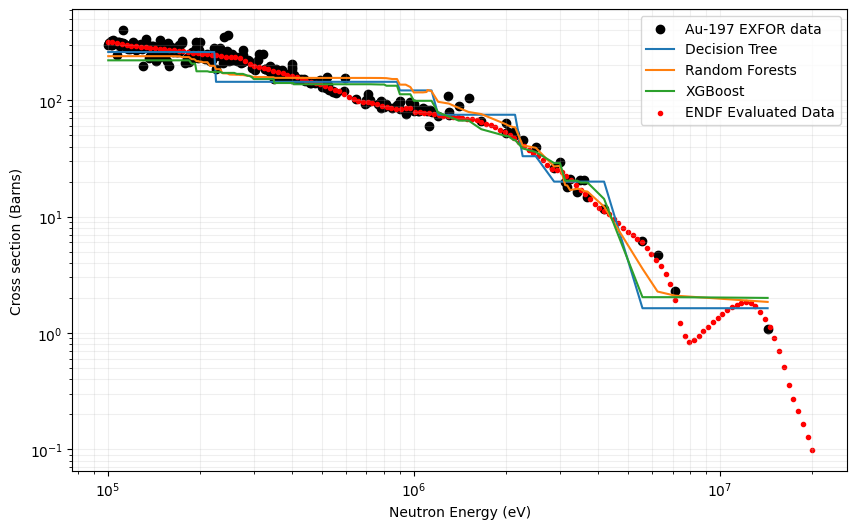

In [76]:
plt.figure(figsize=(10,6))

## Experimental:

plt.scatter(
    10**test["logE"],
    10 ** test["logS"],
    color='black',
    alpha = 1,
    label = "Au-197 EXFOR data",
    marker='o'
)

## Avoiding zigzagging lines

order = np.argsort(X_test["logE"].to_numpy())
energy = 10**X_test["logE"].to_numpy()[order]

for name, model in fitted_models.items():
    prediction = model.predict(X_test)
    plt.plot(
        energy,
        10 ** prediction[order],
        label=name
    )

plt.scatter(ev.energy_eV, ev.sigma_b * 1000, marker='.', label='ENDF Evaluated Data' , color='red')

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Neutron Energy (eV)")
plt.ylabel("Cross section (Barns)")

plt.grid(True, which = "both", alpha=0.2)
plt.legend()

plt.show()

Now we want to evaluate the models...

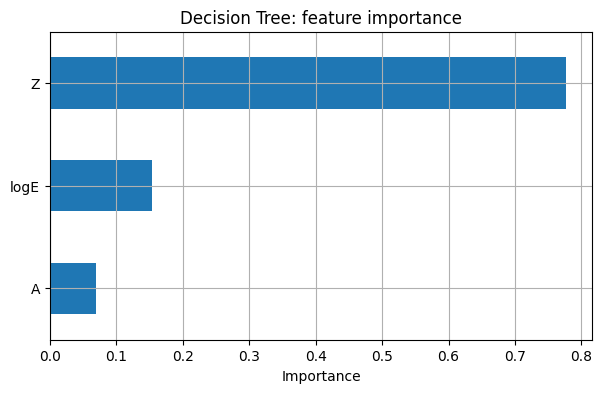

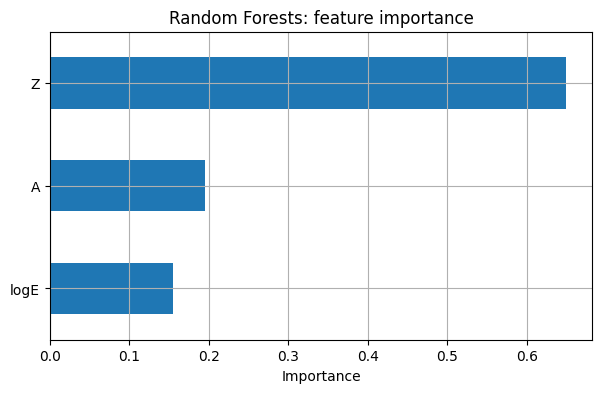

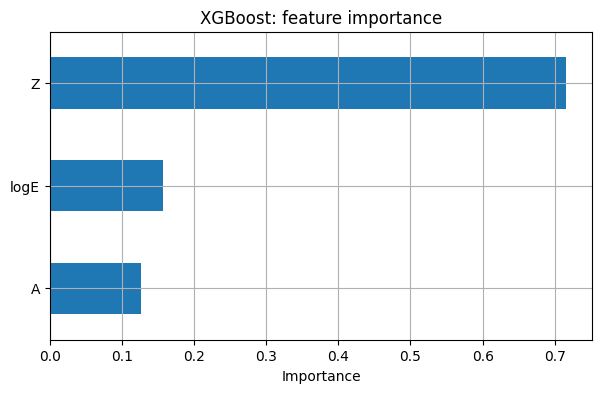

In [50]:
for name, model in fitted_models.items():
    importance = pd.Series(
        model.feature_importances_,
        index = features
    ).sort_values()

    importance.plot.barh(figsize=(7, 4))
    plt.title(f"{name}: feature importance")
    plt.xlabel("Importance")
    plt.grid()
    plt.show()